# Predicting Mortgage Default Early Using Loan Payment History and LSTM/GRU Models

## 1. Setup

First I import the packages I need and set the folder paths. I use relative paths so the notebook can run on another computer as long as the same folder structure is used. The raw zip files from Freddie Mac go in `data/raw`, and the processed files are saved in `data/processed`.

I use loans originated in 2015 Q1, 2016 Q1 and 2017 Q1.

In [1]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd

RAW_DIR = Path("data/raw")
PROCESSED_DIR = Path("data/processed")

QUARTERS = ["2015Q1", "2016Q1", "2017Q1"]

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

## 2. Data Loading

### 2.1 Column names

The Freddie Mac files don't have a header row, so I need to name the columns myself. The order follows the file layout from Freddie Mac's user guide. The origination file has 31 columns.

In [2]:
ORIG_COLS = [
    "fico", "first_pay_date", "first_time_buyer", "maturity_date", "msa",
    "mi_pct", "num_units", "occupancy", "cltv", "dti",
    "orig_upb", "ltv", "orig_rate", "channel", "ppm_flag",
    "amort_type", "state", "property_type", "postal_code", "loan_id",
    "loan_purpose", "orig_term", "num_borrowers", "seller", "super_conforming",
    "pre_harp_id", "special_program", "harp_flag", "valuation_method", "io_flag",
    "vantage_score",
]

print(len(ORIG_COLS))

31


### 2.2 Origination data

The origination file has one row per loan, with the loan information at the time it was originated. I read the files directly from the zip files, so I don't need to unzip them first.

I read all columns as text first. Otherwise some values could change, for example the leading zero in postal codes like "051". I will convert the numeric columns later. I also add a `quarter` column so I know which file each loan comes from.

Note: empty values in `msa` are not errors. They mean the property is not in a metropolitan area.

In [3]:
def read_orig(quarter):
    zip_path = RAW_DIR / f"historical_data_{quarter}.zip"
    with zipfile.ZipFile(zip_path) as z:
        with z.open(f"orig_{quarter}.txt") as f:
            df = pd.read_csv(f, sep="|", header=None, names=ORIG_COLS, dtype=str)
    df["quarter"] = quarter
    return df

orig = pd.concat([read_orig(q) for q in QUARTERS], ignore_index=True)

print(orig.shape)
orig.head()

(964539, 32)


,fico,first_pay_date,first_time_buyer,maturity_date,msa,mi_pct,num_units,occupancy,cltv,dti,...,num_borrowers,seller,super_conforming,pre_harp_id,special_program,harp_flag,valuation_method,io_flag,vantage_score,quarter
0,796,201505,N,203004,43580,0,1,P,72,21,...,1,OTHER,N,NaN,NaN,N,7,N,9999,2015Q1
1,805,201504,N,204503,30700,0,1,P,79,20,...,1,OTHER,N,NaN,NaN,N,7,N,9999,2015Q1
2,730,201503,N,203002,NaN,0,1,P,73,32,...,2,OTHER,N,NaN,NaN,N,7,N,9999,2015Q1
3,762,201505,N,204504,NaN,0,1,P,70,14,...,2,OTHER,N,NaN,NaN,N,7,N,9999,2015Q1
4,777,201505,N,204504,37900,0,1,P,80,40,...,1,OTHER,N,NaN,NaN,N,7,N,9999,2015Q1


### 2.3 Monthly performance data

The performance file has one row per loan per month. It is very large (2015 Q1 alone has about 26 million rows), so I did a few things to keep the memory usage low:

- I only read the 8 columns I need.
- I read the file in chunks of 1 million rows.
- I only keep the first 24 months of each loan, because my model only uses months 1 to 24.

For the delinquency status, "RA" means the property was acquired by the lender (REO), which is the worst possible status. I replace it with 99 so it is counted as 90+ days delinquent. An empty zero balance code means the loan is still active, so I set it to 0.

The result is saved as a parquet file. If the file already exists, this step is skipped, so I don't have to read the large files again every time.

In [4]:
PERF_USECOLS = [0, 1, 2, 3, 4, 7, 8, 10]
PERF_NAMES = ["loan_id", "period", "current_upb", "delinq_status",
              "loan_age", "mod_flag", "zero_bal_code", "current_rate"]

def read_perf(quarter, max_age=24, chunksize=1_000_000):
    out_path = PROCESSED_DIR / f"perf_{quarter}.parquet"
    if out_path.exists():
        print(f"{quarter}: already processed, skipping")
        return

    zip_path = RAW_DIR / f"historical_data_{quarter}.zip"
    pieces = []
    with zipfile.ZipFile(zip_path) as z:
        with z.open(f"perf_{quarter}.txt") as f:
            reader = pd.read_csv(f, sep="|", header=None, usecols=PERF_USECOLS,
                                 dtype=str, chunksize=chunksize)
            for chunk in reader:
                chunk.columns = PERF_NAMES
                chunk["loan_age"] = pd.to_numeric(chunk["loan_age"])
                chunk = chunk[chunk["loan_age"] <= max_age].copy()

                chunk["period"] = pd.to_numeric(chunk["period"])
                chunk["current_upb"] = pd.to_numeric(chunk["current_upb"])
                chunk["current_rate"] = pd.to_numeric(chunk["current_rate"])
                chunk["delinq_status"] = pd.to_numeric(
                    chunk["delinq_status"].replace("RA", "99"), errors="coerce")
                chunk["zero_bal_code"] = pd.to_numeric(chunk["zero_bal_code"]).fillna(0).astype(int)
                chunk["mod_flag"] = chunk["mod_flag"].notna()
                pieces.append(chunk)

    perf = pd.concat(pieces, ignore_index=True)
    perf.to_parquet(out_path, index=False)
    print(f"{quarter}: {len(perf):,} rows saved")

for q in QUARTERS:
    read_perf(q)

2015Q1: already processed, skipping
2016Q1: already processed, skipping
2017Q1: already processed, skipping


## 3. Target Construction

### 3.1 Observation point at month 12

I combine the three quarters and find the month-12 record of each loan. This is the observation point: the model can see months 1 to 12, and it has to predict what happens in months 13 to 24.

To count months forward easily, I convert each period (for example 201605) into a month number, so "12 months later" is just +12.

For a few modified loans, the loan age restarts after the modification, so the same loan can have two month-12 records. In that case I keep the earlier one.

In [5]:
perf = pd.concat(
    [pd.read_parquet(PROCESSED_DIR / f"perf_{q}.parquet").assign(quarter=q) for q in QUARTERS],
    ignore_index=True,
)
perf["loan_id"] = perf["loan_id"].astype("category")

def to_month_index(period):
    return (period // 100) * 12 + period % 100

perf["t"] = to_month_index(perf["period"])

obs = (perf[perf["loan_age"] == 12]
       .sort_values("period")
       .drop_duplicates("loan_id"))

print(f"Loans with a month-12 record: {len(obs):,}")

Loans with a month-12 record: 897,288


### 3.2 Labels

I only keep loans that are still active and not already 90+ days delinquent at month 12. Then I check months 13 to 24. A loan is labeled 1 (default) if, during this period, it becomes 90+ days delinquent or ends with a default-related zero balance code:

- 02: third party sale
- 03: short sale or charge-off
- 09: REO disposition
- 15: whole loan sale

All other loans are labeled 0. Loans that are paid off during months 13 to 24 never get a default record, so they are labeled 0.

Finally, I drop the loans whose months 13 to 24 reach March 2020 or later, so the labels are not affected by the COVID payment relief programs.

In [6]:
obs = obs[(obs["delinq_status"] < 3) & (obs["zero_bal_code"] == 0)].copy()

# months 13 to 24 for each loan
t12 = perf["loan_id"].map(obs.set_index("loan_id")["t"]).astype(float)
in_window = (perf["t"] > t12) & (perf["t"] <= t12 + 12)
is_bad = (perf["delinq_status"] >= 3) | perf["zero_bal_code"].isin([2, 3, 9, 15])

default_ids = perf.loc[in_window & is_bad, "loan_id"].unique()
obs["default"] = obs["loan_id"].isin(default_ids).astype(int)

# drop loans whose label window reaches the COVID period
covid_start = to_month_index(202003)
obs = obs[obs["t"] + 12 < covid_start]

print(f"Loans kept: {len(obs):,}")
print(f"Defaults: {obs['default'].sum():,} ({obs['default'].mean():.3%})")
obs.groupby("quarter")["default"].agg(["size", "sum", "mean"])

Loans kept: 889,676
Defaults: 3,684 (0.414%)


,size,sum,mean
quarter,,,
2015Q1,340112,819,0.002408
2016Q1,281841,1707,0.006057
2017Q1,267723,1158,0.004325


## 4. Exploratory Data Analysis

### 4.1 Cleaning the origination variables

The origination columns were read as text, so I convert the numeric ones to numbers. Freddie Mac uses special codes for missing values, for example 9999 for credit score and 999 for DTI and LTV. If I leave them as numbers, the model would think a borrower has a DTI of 999%, so I replace them with NaN.

Then I merge the origination data with the labels, so each loan has one row with its features and its label.

In [7]:
num_cols = ["fico", "dti", "ltv", "cltv", "orig_rate", "orig_upb",
            "mi_pct", "num_units", "num_borrowers", "orig_term"]
for col in num_cols:
    orig[col] = pd.to_numeric(orig[col])

# Freddie Mac codes for missing values
missing_codes = {"fico": 9999, "dti": 999, "ltv": 999, "cltv": 999,
                 "mi_pct": 999, "num_units": 99, "num_borrowers": 99}
for col, code in missing_codes.items():
    orig[col] = orig[col].replace(code, np.nan)

print("Missing values (%):")
print((orig[num_cols].isna().mean() * 100).round(2))

df = obs[["loan_id", "quarter", "default"]].merge(
    orig.drop(columns="quarter"), on="loan_id", how="left")
print(df.shape)

Missing values (%):
fico             0.00
dti              7.96
ltv              0.00
cltv             0.00
orig_rate        0.00
orig_upb         0.00
mi_pct           0.00
num_units        0.00
num_borrowers    0.00
orig_term        0.00
dtype: float64
(889676, 33)


### 4.2 Default rate by borrower characteristics

Before building the model, I want to check if the origination variables are related to default the way I expect. I group the loans into bands and plot the default rate of each band.

The results match what I expected. Borrowers with lower credit scores, higher LTV and higher DTI default more often. The credit score has the biggest effect: borrowers below 660 default about 20 times more often than borrowers above 780. Loans with only one borrower also default more than loans with two or more borrowers.

Note: for loans originated in 2018 Q1 or before, Freddie Mac only reports the number of borrowers as 1 or "more than 1", so the value 2 here means two or more borrowers.

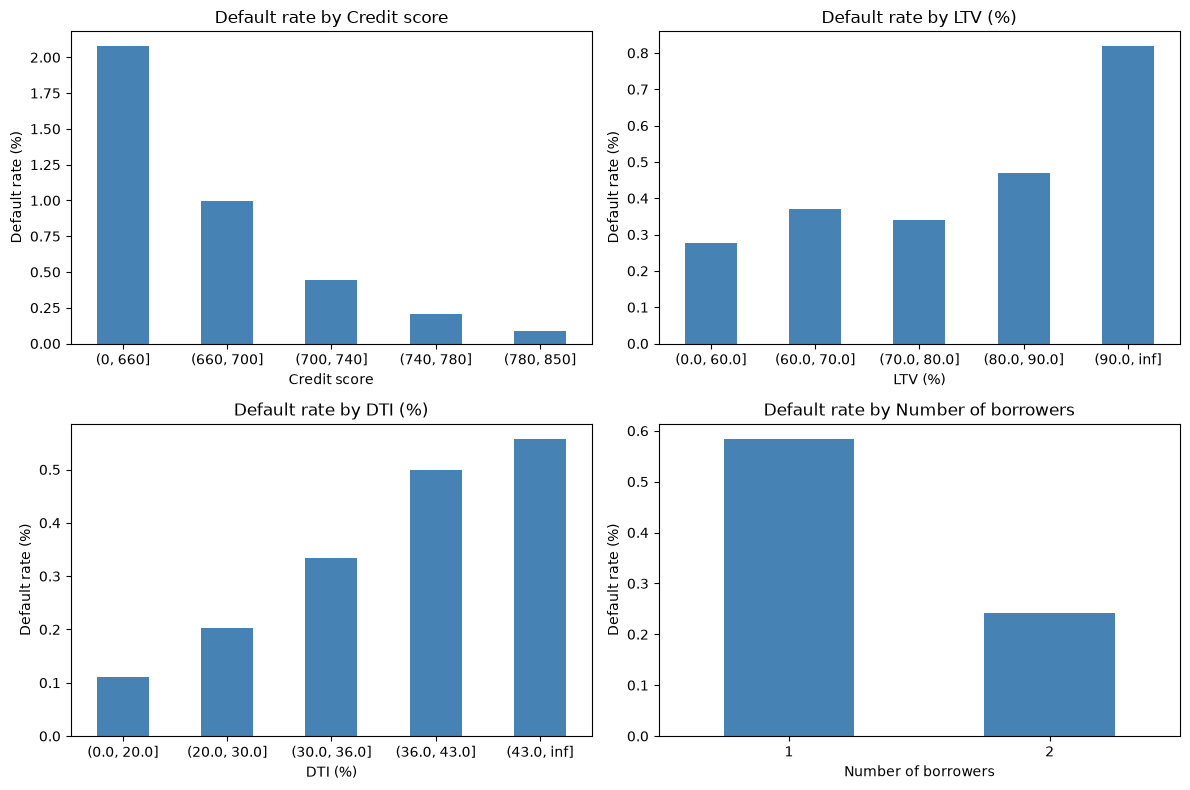

In [8]:
import matplotlib.pyplot as plt

df["fico_band"] = pd.cut(df["fico"], bins=[0, 660, 700, 740, 780, 850])
df["ltv_band"] = pd.cut(df["ltv"], bins=[0, 60, 70, 80, 90, np.inf])
df["dti_band"] = pd.cut(df["dti"], bins=[0, 20, 30, 36, 43, np.inf])

groups = [("fico_band", "Credit score"), ("ltv_band", "LTV (%)"),
          ("dti_band", "DTI (%)"), ("num_borrowers", "Number of borrowers")]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, title) in zip(axes.flat, groups):
    rate = df.groupby(col, observed=True)["default"].mean() * 100
    rate.plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(f"Default rate by {title}")
    ax.set_xlabel(title)
    ax.set_ylabel("Default rate (%)")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### 4.3 Payment history in months 1 to 12

This is the main question of the project: does the payment history in the first 12 months tell us something about default in months 13 to 24?

For each loan, I take the 12 months up to the observation point and count how many months the loan was 30+ days late. I also record the worst delinquency status in these 12 months. I use the calendar months before month 12 instead of the loan age, because the loan age restarts after a modification.

The payment history is a strong signal. About 97.5% of the loans were never late in the first 12 months, and their default rate is only 0.24%. Loans that were late once have a default rate of 2.6%, and loans that were late 3 or more times have a default rate of about 21%.

The worst status chart shows that loans that were 60-89 days late have a higher default rate (31%) than loans that reached 90+ days and then recovered before month 12 (22%). A loan that already recovered seems to be in a better position than a loan that is still behind.

But the history doesn't explain everything. About 57% of the defaults come from loans that were never late in the first 12 months. These borrowers paid on time and then suddenly defaulted, so the payment history alone can't catch them. This is why I also use the origination variables.

Months late (30+ days) in months 1-12
              size   mean
late_group               
0           867151   0.24
1            15141   2.64
2             3320   9.88
3+            4064  20.96 

Worst delinquency status in months 1-12
                size   mean
worst_status               
0             867151   0.24
1              20101   4.42
2               1812  30.74
3+               612  21.73 



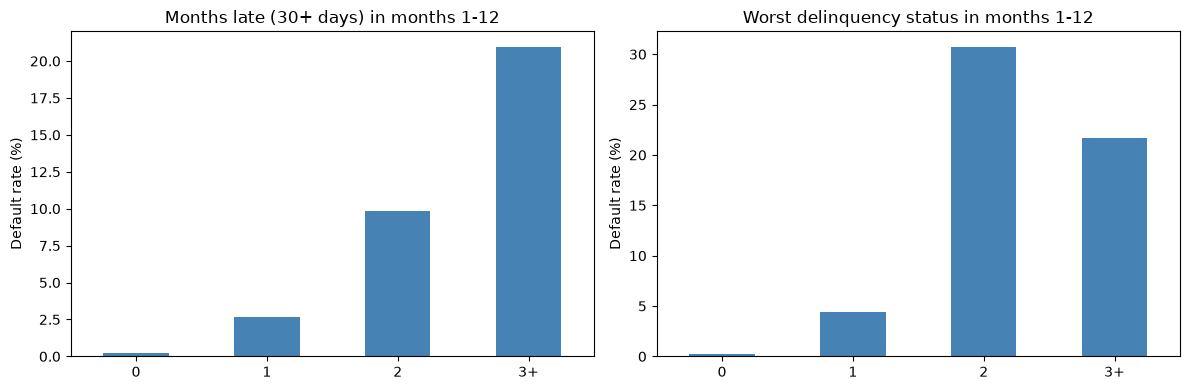

Loans never late in months 1-12: 97.5%
Share of defaults from these loans: 57.1%


In [9]:
hist = perf[(perf["t"] > t12 - 12) & (perf["t"] <= t12) & perf["loan_id"].isin(obs["loan_id"])]

hist_summary = hist.groupby("loan_id", observed=True).agg(
    months_late=("delinq_status", lambda s: (s >= 1).sum()),
    max_status=("delinq_status", "max"),
    n_months=("delinq_status", "size"),
).reset_index()

df = df.merge(hist_summary, on="loan_id", how="left")

df["late_group"] = pd.cut(df["months_late"], bins=[-1, 0, 1, 2, 12],
                          labels=["0", "1", "2", "3+"])
df["worst_status"] = pd.cut(df["max_status"], bins=[-1, 0, 1, 2, 99],
                            labels=["0", "1", "2", "3+"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title in [(axes[0], "late_group", "Months late (30+ days) in months 1-12"),
                       (axes[1], "worst_status", "Worst delinquency status in months 1-12")]:
    summary = df.groupby(col, observed=True)["default"].agg(["size", "mean"])
    print(title)
    print(summary.assign(mean=lambda x: (x["mean"] * 100).round(2)), "\n")
    (summary["mean"] * 100).plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Default rate (%)")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

clean = df["months_late"] == 0
print(f"Loans never late in months 1-12: {clean.mean():.1%}")
print(f"Share of defaults from these loans: {df.loc[clean, 'default'].sum() / df['default'].sum():.1%}")

### 4.4 How the payment history changes month by month

To see why a sequence model could help, I plot the share of loans that are 30+ days late in each of the 12 months, separately for loans that default later and loans that don't.

For loans that don't default, the share stays flat at around 0.3-0.4% in every month. For loans that default, it starts at about 2% in month 1 and keeps going up to about 27% in month 12. So the months closer to the observation point carry more information, and the trend over time also matters, not only the total number of late months. This is what an LSTM or GRU should be able to learn. It also gives a reason for my experiment comparing 6 vs. 12 months of history.

default     0      1
month               
1        0.37   1.85
2        0.30   3.28
3        0.22   4.57
4        0.22   6.34
5        0.25   7.83
6        0.30  10.85
7        0.37  13.32
8        0.40  15.42
9        0.40  18.02
10       0.41  20.17
11       0.37  23.62
12       0.38  27.50


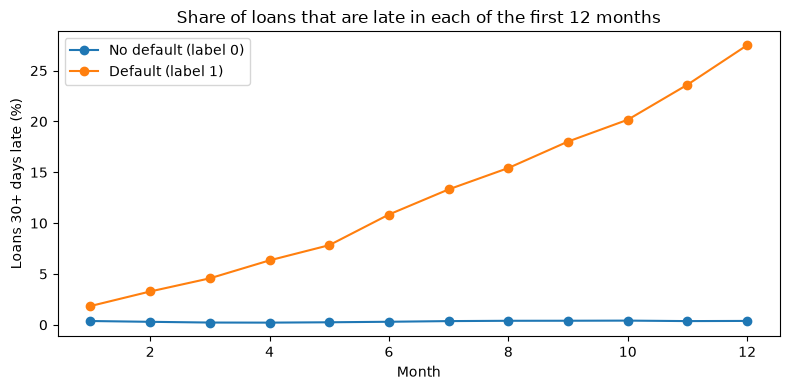

In [10]:
hist2 = hist.merge(df[["loan_id", "default"]], on="loan_id")
hist2["month"] = hist2["t"] - hist2["loan_id"].map(obs.set_index("loan_id")["t"]).astype(int) + 12
hist2["is_late"] = hist2["delinq_status"] >= 1

trend = hist2.groupby(["month", "default"])["is_late"].mean().unstack() * 100
print(trend.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(trend.index, trend[0], marker="o", label="No default (label 0)")
ax.plot(trend.index, trend[1], marker="o", label="Default (label 1)")
ax.set_xlabel("Month")
ax.set_ylabel("Loans 30+ days late (%)")
ax.set_title("Share of loans that are late in each of the first 12 months")
ax.legend()
plt.tight_layout()
plt.show()

### 4.5 Default rate by state

Earlier I saw that 2016 Q1 loans have a much higher default rate (0.61%) than the other two quarters. For these loans, months 13 to 24 fall around early 2017 to early 2018, which includes Hurricane Harvey (Texas, August 2017) and Hurricane Irma (Florida, September 2017). So I check the default rate by state, and then compare Florida and Texas with the other states in each quarter.

Florida has by far the highest default rate (1.45%), and Texas is third (0.73%). The second table shows that this comes from the 2016 Q1 loans: in Florida, their default rate is 3.48%, compared with 0.32% in the other states. For 2015 Q1 and 2017 Q1, Florida and Texas are close to the other states. So a large part of the difference between quarters is caused by the hurricanes, not by the borrowers themselves.

I keep these loans in the data, because natural disasters are also a real source of credit risk. But it means part of the defaults are hard to predict from the payment history, and I will mention this in the limitations.

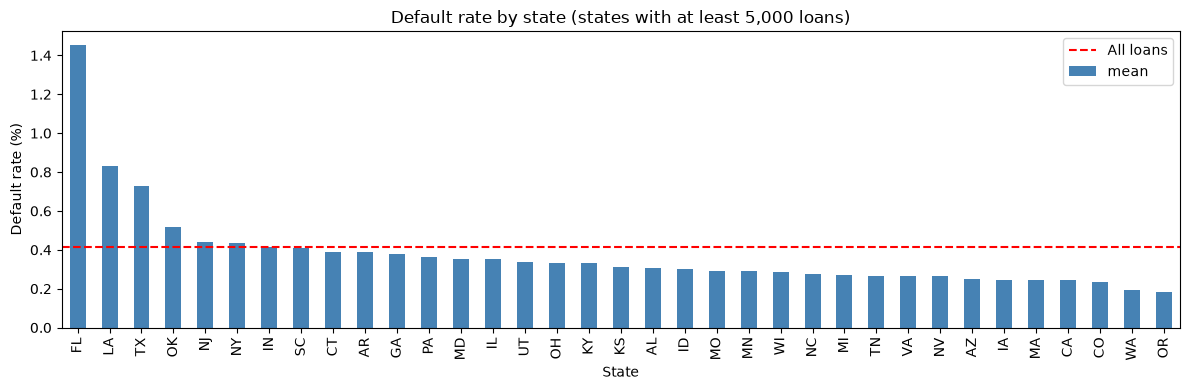

region,FL,Other,TX
quarter,,,
2015Q1,0.33,0.23,0.32
2016Q1,3.48,0.32,1.42
2017Q1,0.61,0.42,0.46


In [11]:
state = df.groupby("state")["default"].agg(["size", "mean"])
state = state[state["size"] >= 5000].sort_values("mean", ascending=False)

fig, ax = plt.subplots(figsize=(12, 4))
(state["mean"] * 100).plot(kind="bar", ax=ax, color="steelblue")
ax.axhline(df["default"].mean() * 100, color="red", linestyle="--", label="All loans")
ax.set_title("Default rate by state (states with at least 5,000 loans)")
ax.set_xlabel("State")
ax.set_ylabel("Default rate (%)")
ax.legend()
plt.tight_layout()
plt.show()

df["region"] = np.where(df["state"].isin(["FL", "TX"]), df["state"], "Other")
(df.pivot_table(index="quarter", columns="region", values="default", aggfunc="mean") * 100).round(2)

## 5. Train, Validation and Test Split

Each loan has only one observation, so splitting by loan makes sure the same loan never appears in two sets. I use 70% of the loans for training, 15% for validation (to tune the models and choose the settings) and 15% for testing (only used at the end for the final results).

The split is stratified by quarter and default, so each set has the same default rate and the same mix of the three quarters. This matters because defaults are rare, and 2016 Q1 has a higher default rate because of the hurricanes. I fix the random seed so the split is the same every time I run the notebook.

In [12]:
from sklearn.model_selection import train_test_split

strata = df["quarter"] + "_" + df["default"].astype(str)

train_ids, temp_ids = train_test_split(
    df["loan_id"], test_size=0.30, stratify=strata, random_state=42)
val_ids, test_ids = train_test_split(
    temp_ids, test_size=0.50, stratify=strata.loc[temp_ids.index], random_state=42)

df["split"] = "train"
df.loc[df["loan_id"].isin(val_ids), "split"] = "val"
df.loc[df["loan_id"].isin(test_ids), "split"] = "test"

df.groupby("split")["default"].agg(["size", "sum", "mean"])

,size,sum,mean
split,,,
test,133452,553,0.004144
train,622773,2579,0.004141
val,133451,552,0.004136


## 6. Baseline Models (Origination Data Only)

### 6.1 Feature preparation

The two baselines only use the origination variables, so I can later see how much the payment history adds.

- Numeric variables: a few loans have missing values. DTI is missing for about 8% of the loans, and credit score, LTV, CLTV, MI percentage and number of units are missing for only a few loans. I fill them with the median of the training set. For DTI, I also add a flag for missing values, since the missing DTI loans could be different from the others.
- Loan amount is very skewed, so I take the log.
- Categorical variables (occupancy, loan purpose, property type, first-time buyer, channel, state and HARP flag) are one-hot encoded.
- Numeric variables are standardized. The median and the scaler are fitted on the training set only, so no information from the validation or test set is used.

In [13]:
from sklearn.preprocessing import StandardScaler

num_features = ["fico", "dti", "ltv", "cltv", "orig_rate", "orig_upb",
                "mi_pct", "num_units", "num_borrowers", "orig_term"]
cat_features = ["occupancy", "loan_purpose", "property_type", "first_time_buyer",
                "channel", "state", "harp_flag"]

X = df[num_features + cat_features].copy()
X["dti_missing"] = X["dti"].isna().astype(int)
X["orig_upb"] = np.log(X["orig_upb"])

train_mask = df["split"] == "train"
for col in num_features:
    X[col] = X[col].fillna(X.loc[train_mask, col].median())

X = pd.get_dummies(X, columns=cat_features, drop_first=True, dtype=float)

scaler = StandardScaler()
scaler.fit(X.loc[train_mask, num_features])
X[num_features] = scaler.transform(X[num_features])

y = df["default"].values
X_train, y_train = X[df["split"] == "train"].values, y[df["split"] == "train"]
X_val, y_val = X[df["split"] == "val"].values, y[df["split"] == "val"]
X_test, y_test = X[df["split"] == "test"].values, y[df["split"] == "test"]

print(X_train.shape, X_val.shape, X_test.shape)
print("Missing values left:", X.isna().sum().sum())

(622773, 77) (133451, 77) (133452, 77)
Missing values left: 0


### 6.2 Logistic regression

I train a logistic regression on the origination features, once without class weights and once with balanced class weights. I evaluate on the validation set with three metrics:

- ROC-AUC: how well the model ranks defaulting loans above non-defaulting loans (0.5 is random).
- PR-AUC: more informative when the data is very imbalanced. A random model would get about 0.004 here, which is the default rate.
- Recall at top 5%: if a lender can only review the 5% riskiest loans, what share of all defaults is caught. This is the early-warning use case from my proposal.

I also add a simple rule as a reference: pick the 5% of loans with the lowest credit scores.

The logistic regression gets a ROC-AUC of about 0.84 and catches about 32-33% of the defaults in the top 5%, compared with 24% for the credit score rule. So even with only the origination data, the model does clearly better than looking at the credit score alone. The PR-AUC is low (about 0.026), but it is still around 6 times better than random, which is normal when defaults are this rare.

Class weights don't change the results much (ROC-AUC 0.838 vs. 0.841). The three metrics only depend on how the loans are ranked, and logistic regression ranks them in almost the same order with or without weights. The weights mainly change the size of the predicted probabilities.

The validation set has only about 550 defaults, so small differences like this could just be noise. I will keep this in mind when I compare models later. This logistic regression is the baseline that the models with payment history need to beat.

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

def evaluate(y_true, y_prob, top=0.05):
    n_top = int(len(y_prob) * top)
    top_idx = np.argsort(y_prob)[::-1][:n_top]
    recall_top = y_true[top_idx].sum() / y_true.sum()
    return {"ROC-AUC": roc_auc_score(y_true, y_prob),
            "PR-AUC": average_precision_score(y_true, y_prob),
            f"Recall@top{int(top * 100)}%": recall_top}

results = {}
for name, cw in [("LogReg", None), ("LogReg (balanced)", "balanced")]:
    model = LogisticRegression(max_iter=1000, class_weight=cw)
    model.fit(X_train, y_train)
    results[name] = evaluate(y_val, model.predict_proba(X_val)[:, 1])

# simple rule: the lower the credit score, the riskier
fico_val = df.loc[df["split"] == "val", "fico"].values
results["Lowest FICO rule"] = evaluate(y_val, -np.nan_to_num(fico_val, nan=850))

pd.DataFrame(results).T.round(4)

,ROC-AUC,PR-AUC,Recall@top5%
LogReg,0.8381,0.0254,0.3188
LogReg (balanced),0.8407,0.0263,0.3333
Lowest FICO rule,0.7536,0.0152,0.2391


### 6.3 Training functions for the neural networks

Before training the neural networks, I write a few helper functions that I will reuse for the feed-forward network and later for the LSTM and GRU, so all models are trained and evaluated the same way.

- `to_loader` turns the arrays into PyTorch batches.
- `predict` returns the model output for a dataset.
- `train_model` trains a model with the Adam optimizer and binary cross-entropy loss. After each epoch, it records the training loss, the validation loss and the validation metrics. It keeps the weights from the epoch with the best validation PR-AUC, so I don't end up with an overfitted model from the last epoch.

The loss function has a `pos_weight` option, which gives more weight to the defaults. I will use it later to test different ways of handling the class imbalance.

In [15]:
import copy
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

def to_loader(arrays, y, batch_size=1024, shuffle=False):
    tensors = [torch.tensor(a, dtype=torch.float32) for a in arrays]
    tensors.append(torch.tensor(y, dtype=torch.float32))
    return DataLoader(TensorDataset(*tensors), batch_size=batch_size, shuffle=shuffle)

def predict(model, loader):
    model.eval()
    logits = []
    with torch.no_grad():
        for *inputs, _ in loader:
            inputs = [x.to(device) for x in inputs]
            logits.append(model(*inputs).squeeze(1).cpu())
    return torch.cat(logits)

def train_model(model, train_loader, val_loader, y_val, epochs=10, lr=1e-3, pos_weight=1.0):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(float(pos_weight), device=device))
    val_loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(float(pos_weight)))
    y_val_tensor = torch.tensor(y_val, dtype=torch.float32)

    history = []
    best_score, best_state = -1, None
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0
        for *inputs, yb in train_loader:
            inputs = [x.to(device) for x in inputs]
            yb = yb.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(*inputs).squeeze(1), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(yb)

        val_logits = predict(model, val_loader)
        val_loss = val_loss_fn(val_logits, y_val_tensor).item()
        scores = evaluate(y_val, torch.sigmoid(val_logits).numpy())
        history.append({"epoch": epoch,
                        "train_loss": total_loss / len(train_loader.dataset),
                        "val_loss": val_loss, **scores})
        print(f"Epoch {epoch:2d} | train loss {history[-1]['train_loss']:.4f} | "
              f"val loss {val_loss:.4f} | val ROC-AUC {scores['ROC-AUC']:.4f} | "
              f"val PR-AUC {scores['PR-AUC']:.4f}")

        if scores["PR-AUC"] > best_score:
            best_score = scores["PR-AUC"]
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

Device: cpu


Training all the models takes almost two hours on my laptop, so `train_or_load` saves each trained model and its training history in the `models` folder. If the files already exist, the model is loaded instead of trained again, so the notebook can be re-run quickly.

In [16]:
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

def train_or_load(name, model, *args, **kwargs):
    weight_path = MODEL_DIR / f"{name}.pt"
    hist_path = MODEL_DIR / f"{name}_history.csv"
    if weight_path.exists() and hist_path.exists():
        model.load_state_dict(torch.load(weight_path))
        model.to(device)
        print(f"Loaded saved model: {name}")
        return model, pd.read_csv(hist_path)
    model, history = train_model(model, *args, **kwargs)
    torch.save(model.state_dict(), weight_path)
    history.to_csv(hist_path, index=False)
    return model, history

### 6.4 Feed-forward neural network

The second baseline is a simple feed-forward network with the same origination features as the logistic regression. It has two hidden layers (64 and 32 units) with ReLU activations and dropout of 0.2 after the first layer to reduce overfitting. I train it for 10 epochs with a learning rate of 0.001 and a batch size of 1,024, without class weights for now.

I plot the training and validation loss to check for overfitting, and compare the result with the logistic regression.

Loaded saved model: ffn


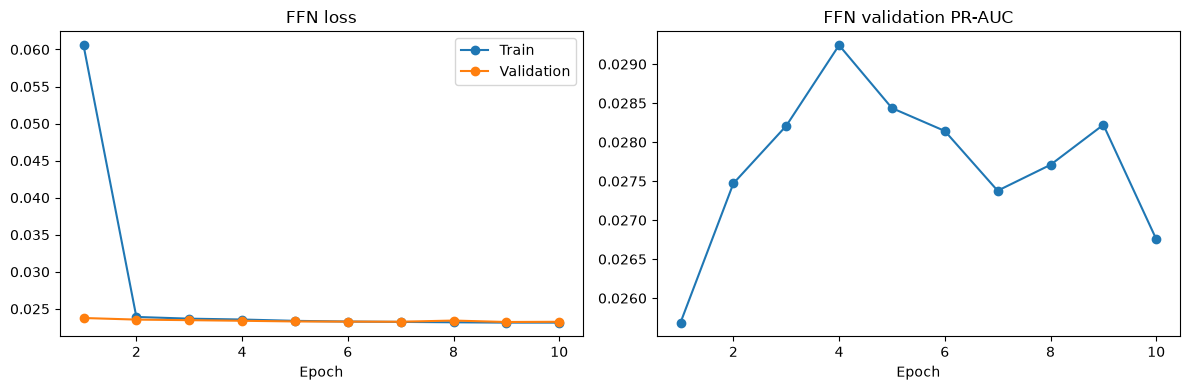

,ROC-AUC,PR-AUC,Recall@top5%
LogReg,0.8381,0.0254,0.3188
LogReg (balanced),0.8407,0.0263,0.3333
Lowest FICO rule,0.7536,0.0152,0.2391
FFN,0.8358,0.0292,0.3261


In [17]:
import matplotlib.pyplot as plt

class FFN(nn.Module):
    def __init__(self, n_features, hidden=64, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2),
            nn.ReLU(),
            nn.Linear(hidden // 2, 1),
        )

    def forward(self, x):
        return self.net(x)

train_loader = to_loader([X_train], y_train, shuffle=True)
val_loader = to_loader([X_val], y_val, batch_size=4096)

ffn = FFN(n_features=X_train.shape[1])
ffn, ffn_history = train_or_load("ffn", ffn, train_loader, val_loader, y_val, epochs=10, lr=1e-3)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ffn_history["epoch"], ffn_history["train_loss"], marker="o", label="Train")
axes[0].plot(ffn_history["epoch"], ffn_history["val_loss"], marker="o", label="Validation")
axes[0].set_title("FFN loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(ffn_history["epoch"], ffn_history["PR-AUC"], marker="o")
axes[1].set_title("FFN validation PR-AUC")
axes[1].set_xlabel("Epoch")
plt.tight_layout()
plt.show()

results["FFN"] = evaluate(y_val, torch.sigmoid(predict(ffn, val_loader)).numpy())
pd.DataFrame(results).T.round(4)

The training and validation loss drop quickly after the first epoch and then stay almost flat, and the two curves are very close, so the model is not overfitting. The validation PR-AUC is highest at epoch 4, and the weights from this epoch are kept.

The feed-forward network performs about the same as the logistic regression (ROC-AUC 0.836 vs. 0.838-0.841, recall at top 5% of 32.6% vs. 31.9-33.3%). Its PR-AUC is slightly higher, but the epoch was chosen using the same validation set, so this number is a bit optimistic. With only the origination data, a more complex model doesn't add much. To do better, the model needs new information, which is what the payment history should provide.

## 7. Sequence Models (Payment History + Origination Data)

### 7.1 Building the payment history sequences

An LSTM needs the input as a 3D array: (number of loans, number of months, number of features per month). For each loan I build a sequence of 12 months, and each month has 7 features:

- 4 columns for the delinquency status, one-hot encoded: current, 30-59 days, 60-89 days, and 90+ days. I use one-hot encoding because the status is a category, and statuses above 3 are very rare.
- The current balance divided by the original loan amount. Normally this goes down slowly every month, so a balance that stops going down could be a warning sign.
- The modification flag.
- A flag that is 1 if the month is observed. About 2.5% of the loans have fewer than 12 months of records (Freddie Mac bought them a few months after origination), so the missing months are filled with zeros and this flag tells the model which months are real.

The rows are in the same order as the origination features, so each loan's sequence matches its static features and its label.

In [18]:
row_of_loan = pd.Series(np.arange(len(df)), index=df["loan_id"].astype(str))

seq_data = hist[["loan_id", "t", "delinq_status", "current_upb", "mod_flag"]].copy()
seq_data["row"] = seq_data["loan_id"].astype(str).map(row_of_loan).values
seq_data["month"] = seq_data["t"] - seq_data["loan_id"].map(obs.set_index("loan_id")["t"]).astype(int) + 12

n_loans, n_months, n_seq_features = len(df), 12, 7
seq = np.zeros((n_loans, n_months, n_seq_features), dtype=np.float32)

rows = seq_data["row"].values
cols = seq_data["month"].values - 1

# features 0-3: delinquency status (0, 1, 2, 3+), one-hot
status = seq_data["delinq_status"].clip(upper=3).astype(int).values
seq[rows, cols, status] = 1
# feature 4: current balance / original loan amount
upb_ratio = seq_data["current_upb"].values / df["orig_upb"].values[rows]
seq[rows, cols, 4] = np.nan_to_num(upb_ratio)
# feature 5: modification flag
seq[rows, cols, 5] = seq_data["mod_flag"].astype(float).values
# feature 6: month is observed
seq[rows, cols, 6] = 1

seq_train = seq[(df["split"] == "train").values]
seq_val = seq[(df["split"] == "val").values]
seq_test = seq[(df["split"] == "test").values]

print(seq.shape)
print(seq_train.shape, seq_val.shape, seq_test.shape)
print("Share of months observed:", seq[:, :, 6].mean().round(4))

(889676, 12, 7)
(622773, 12, 7) (133451, 12, 7) (133452, 12, 7)
Share of months observed: 0.9963


### 7.2 LSTM model

The model has two branches:

- The LSTM reads the 12 months of payment history one month at a time. I use its output at the last month (month 12), which summarizes the whole history.
- The origination features don't change over time, so they go through a dense layer with 32 units and ReLU.

The two outputs are concatenated and passed through a dense layer with 32 units, dropout of 0.2, and a final output unit for the default probability. The LSTM has a hidden size of 32. I use the same training setup as the feed-forward network (Adam, learning rate 0.001, batch size 1,024, 10 epochs, no class weights), so the only difference is the payment history.

I write the model so that the recurrent layer can be either an LSTM or a GRU, which I will use for the LSTM vs. GRU experiment.

Loaded saved model: lstm


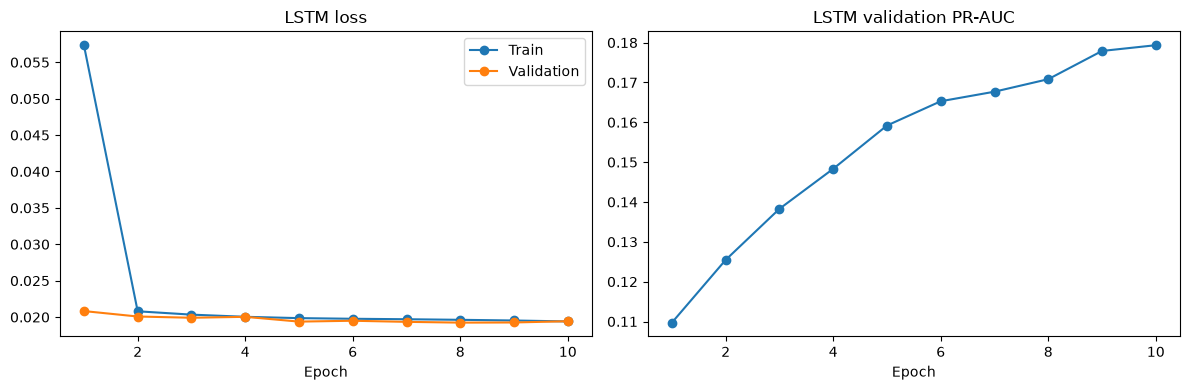

,ROC-AUC,PR-AUC,Recall@top5%
LogReg,0.8381,0.0254,0.3188
LogReg (balanced),0.8407,0.0263,0.3333
Lowest FICO rule,0.7536,0.0152,0.2391
FFN,0.8358,0.0292,0.3261
LSTM,0.9033,0.1794,0.5870


In [19]:
class SeqModel(nn.Module):
    def __init__(self, n_seq_features, n_static, hidden=32, rnn_type="lstm", dropout=0.2):
        super().__init__()
        rnn_class = nn.LSTM if rnn_type == "lstm" else nn.GRU
        self.rnn = rnn_class(n_seq_features, hidden, batch_first=True)
        self.static = nn.Sequential(nn.Linear(n_static, 32), nn.ReLU())
        self.head = nn.Sequential(
            nn.Linear(hidden + 32, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1),
        )

    def forward(self, seq, static):
        out, _ = self.rnn(seq)
        last = out[:, -1, :]
        combined = torch.cat([last, self.static(static)], dim=1)
        return self.head(combined)

seq_train_loader = to_loader([seq_train, X_train], y_train, shuffle=True)
seq_val_loader = to_loader([seq_val, X_val], y_val, batch_size=4096)

torch.manual_seed(42)
lstm = SeqModel(n_seq_features=seq_train.shape[2], n_static=X_train.shape[1], rnn_type="lstm")
lstm, lstm_history = train_or_load("lstm", lstm, seq_train_loader, seq_val_loader, y_val, epochs=10, lr=1e-3)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(lstm_history["epoch"], lstm_history["train_loss"], marker="o", label="Train")
axes[0].plot(lstm_history["epoch"], lstm_history["val_loss"], marker="o", label="Validation")
axes[0].set_title("LSTM loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(lstm_history["epoch"], lstm_history["PR-AUC"], marker="o")
axes[1].set_title("LSTM validation PR-AUC")
axes[1].set_xlabel("Epoch")
plt.tight_layout()
plt.show()

results["LSTM"] = evaluate(y_val, torch.sigmoid(predict(lstm, seq_val_loader)).numpy())
pd.DataFrame(results).T.round(4)

Adding the payment history makes a big difference. Compared with the feed-forward network, which uses the same origination features and the same training setup, the LSTM improves the ROC-AUC from 0.836 to 0.903, the PR-AUC from 0.029 to 0.179, and the recall at top 5% from 32.6% to 58.7%. So if a lender reviews the 5% riskiest loans, the LSTM catches almost 60% of the defaults, compared with about 32% for the origination-only models and 24% for the credit score rule.

This result makes sense given the EDA: loans that were late in the first 12 months are only 2.5% of the loans but contain about 43% of the defaults, so the model can put them at the top of the list. The sequence only uses information up to month 12 and the label comes from months 13 to 24, so there is no overlap between the inputs and the target.

The loss curves show no overfitting. The validation PR-AUC is still going up at epoch 10, so the model has probably not finished learning. I will try training for more epochs in the experiments.

## 8. Experiments

### 8.1 Experiment 1: Number of epochs

In the first LSTM run, the validation PR-AUC was still going up at epoch 10, so the model probably stopped too early. Here I train the same LSTM for 30 epochs to see if it keeps improving or starts to overfit. The training function keeps the weights from the epoch with the best validation PR-AUC, so training longer can't make the final model worse on the validation set.

To keep the experiments organized, I write a small function that builds the data loaders, trains a model and saves its results and training history, so every experiment is run the same way.

--- LSTM (30 epochs) ---
Loaded saved results


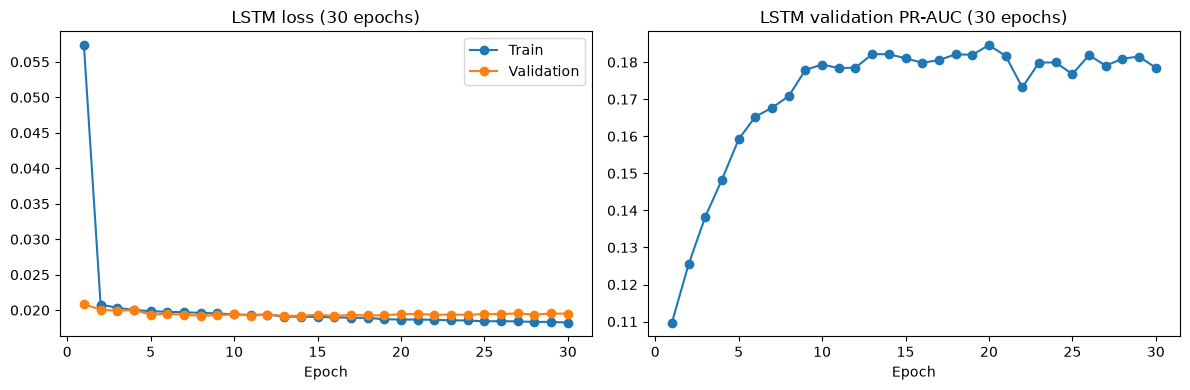

Best epoch: 20


,ROC-AUC,PR-AUC,Recall@top5%
LSTM (10 epochs),0.9033,0.1794,0.5870
LSTM (30 epochs),0.9010,0.1846,0.5779


In [20]:
exp_results = {"LSTM (10 epochs)": results["LSTM"]}
exp_histories = {"LSTM (10 epochs)": lstm_history}

def run_experiment(name, rnn_type="lstm", seq_tr=seq_train, seq_va=seq_val,
                   epochs=30, lr=1e-3, pos_weight=1.0, hidden=32, seed=42):
    print(f"--- {name} ---")
    torch.manual_seed(seed)
    model = SeqModel(n_seq_features=seq_tr.shape[2], n_static=X_train.shape[1],
                     hidden=hidden, rnn_type=rnn_type)
    hist_path = MODEL_DIR / f"{name}_history.csv"
    weight_path = MODEL_DIR / f"{name}.pt"

    if hist_path.exists():
        history = pd.read_csv(hist_path)
        if weight_path.exists():
            model.load_state_dict(torch.load(weight_path))
            model.to(device)
        print("Loaded saved results")
    else:
        train_loader = to_loader([seq_tr, X_train], y_train, shuffle=True)
        val_loader = to_loader([seq_va, X_val], y_val, batch_size=4096)
        model, history = train_model(model, train_loader, val_loader, y_val,
                                     epochs=epochs, lr=lr, pos_weight=pos_weight)
        history.to_csv(hist_path, index=False)
        torch.save(model.state_dict(), weight_path)

    best = history.loc[history["PR-AUC"].idxmax()]
    exp_results[name] = {k: best[k] for k in ["ROC-AUC", "PR-AUC", "Recall@top5%"]}
    exp_histories[name] = history
    return model

lstm30 = run_experiment("LSTM (30 epochs)", rnn_type="lstm", epochs=30)

h = exp_histories["LSTM (30 epochs)"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(h["epoch"], h["train_loss"], marker="o", label="Train")
axes[0].plot(h["epoch"], h["val_loss"], marker="o", label="Validation")
axes[0].set_title("LSTM loss (30 epochs)")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(h["epoch"], h["PR-AUC"], marker="o")
axes[1].set_title("LSTM validation PR-AUC (30 epochs)")
axes[1].set_xlabel("Epoch")
plt.tight_layout()
plt.show()

print("Best epoch:", h.loc[h["PR-AUC"].idxmax(), "epoch"])
pd.DataFrame(exp_results).T.round(4)

The validation PR-AUC goes up quickly in the first 10 epochs and then stays around 0.178-0.184. The best epoch is 20 (PR-AUC 0.185), but it is only slightly better than epochs 10 to 15. After about epoch 15, the training loss keeps going down while the validation loss starts to go up a little, which is the beginning of overfitting.

Compared with 10 epochs, training for 30 epochs gives almost the same result (PR-AUC 0.185 vs. 0.179, recall at top 5% of 57.8% vs. 58.7%), and these differences are within the noise. So most of the learning happens in the first 10-15 epochs. For the next experiments, I use 15 epochs, which is enough for the model to reach this level and saves time.

The first 10 epochs of this run are the same as the earlier 10-epoch run, which confirms that fixing the random seed makes the training reproducible.

### 8.2 Experiment 2: LSTM vs. GRU

GRU is a simpler version of LSTM with fewer parameters, so it trains faster. My sequences are only 12 months long, so a GRU might be enough.

Earlier I saw that the results can change by about 0.01 in ROC-AUC just because of randomness, and the validation set only has about 550 defaults. So instead of comparing one run of each, I train both models with 3 different random seeds (15 epochs each) and compare the average and the standard deviation. Everything else is the same, so the only difference is the type of recurrent layer.

In [21]:
for seed in [42, 1, 2]:
    run_experiment(f"LSTM seed {seed}", rnn_type="lstm", epochs=15, seed=seed)
    run_experiment(f"GRU seed {seed}", rnn_type="gru", epochs=15, seed=seed)

compare = pd.DataFrame({k: v for k, v in exp_results.items() if "seed" in k}).T
compare["model"] = compare.index.str.split().str[0]
print(compare.round(4))
compare.groupby("model").agg(["mean", "std"]).round(4)

--- LSTM seed 42 ---
Loaded saved results
--- GRU seed 42 ---
Loaded saved results
--- LSTM seed 1 ---
Loaded saved results
--- GRU seed 1 ---
Loaded saved results
--- LSTM seed 2 ---
Loaded saved results
--- GRU seed 2 ---
Loaded saved results
              ROC-AUC  PR-AUC  Recall@top5% model
LSTM seed 42   0.9035  0.1822        0.5779  LSTM
GRU seed 42    0.9027  0.1832        0.5906   GRU
LSTM seed 1    0.9036  0.1764        0.5942  LSTM
GRU seed 1     0.9034  0.1818        0.5888   GRU
LSTM seed 2    0.9038  0.1779        0.5942  LSTM
GRU seed 2     0.9012  0.1776        0.5779   GRU


ROC-AUC          PR-AUC         Recall@top5%        
         mean     std    mean     std         mean     std
model                                                     
GRU    0.9024  0.0011  0.1809  0.0029       0.5857  0.0069
LSTM   0.9036  0.0002  0.1788  0.0030       0.5888  0.0094

The LSTM and the GRU perform almost the same. The average ROC-AUC is 0.904 for the LSTM and 0.902 for the GRU, the PR-AUC is 0.179 vs. 0.181, and the recall at top 5% is 58.9% vs. 58.6%. All these differences are about the same size as the standard deviation across seeds or smaller, and neither model is better on all three metrics, so I can't say that one is better than the other. This makes sense because the sequences are only 12 months long. The extra gate in the LSTM is mainly useful for remembering information over long sequences, so the simpler GRU is enough here.

The results are also very stable across seeds (the standard deviation of ROC-AUC is at most 0.001). This means the training itself is stable, and most of the uncertainty comes from the small number of defaults in the validation set, not from the random initialization.

I keep using the LSTM for the next experiments, so they can be compared directly with the LSTM results above.

### 8.3 Experiment 3: Length of the payment history

The EDA showed that the months close to the observation point carry the most information. So I test how much history the model really needs. I train the LSTM with only the last 3 months and the last 6 months of payment history (months 10-12 and months 7-12) and compare them with the full 12 months from Experiment 2. Everything else stays the same, including the origination features, 15 epochs and the 3 seeds.

If the shorter histories perform almost as well, it means a lender would only need recent payment data to get most of the benefit.

In [22]:
for n_months in [3, 6]:
    for seed in [42, 1, 2]:
        run_experiment(f"LSTM {n_months}m seed {seed}", rnn_type="lstm",
                       seq_tr=seq_train[:, -n_months:, :], seq_va=seq_val[:, -n_months:, :],
                       epochs=15, seed=seed)

length = pd.DataFrame({k: v for k, v in exp_results.items() if k.startswith("LSTM") and "seed" in k}).T
length["history"] = length.index.map(lambda k: k.split()[1] if "m" in k.split()[1] else "12m")
length.groupby("history").agg(["mean", "std"]).round(4)

--- LSTM 3m seed 42 ---
Loaded saved results
--- LSTM 3m seed 1 ---
Loaded saved results
--- LSTM 3m seed 2 ---
Loaded saved results
--- LSTM 6m seed 42 ---
Loaded saved results
--- LSTM 6m seed 1 ---
Loaded saved results
--- LSTM 6m seed 2 ---
Loaded saved results


ROC-AUC          PR-AUC         Recall@top5%        
           mean     std    mean     std         mean     std
history                                                     
12m      0.9036  0.0002  0.1788  0.0030       0.5888  0.0094
3m       0.8955  0.0009  0.1685  0.0033       0.5556  0.0055
6m       0.9017  0.0002  0.1765  0.0043       0.5773  0.0082

Using the last 6 months gives almost the same result as using all 12 months (ROC-AUC 0.902 vs. 0.904, PR-AUC 0.177 vs. 0.179, recall at top 5% of 57.7% vs. 58.9%), and these differences are within the variation across seeds. Using only the last 3 months is clearly worse: the ROC-AUC drops by about 0.008 and the PR-AUC by about 0.010, which is several times the standard deviation, and the recall at top 5% drops to 55.6%. So the model needs around 6 months of history, and the older months add very little. With only 3 months, the model probably can't see the trend of payments getting worse over time.

Still, even 3 months of history gives a PR-AUC of 0.169, compared with 0.029 for the feed-forward network without any history. So most of the gain from the payment history comes from the most recent months, which matches the EDA. In practice, this means a lender could start using the model about 6 months after a loan is originated instead of waiting a full year.

### 8.4 Experiment 4: Handling the class imbalance

Only 0.4% of the loans default, and so far I trained without class weights. Here I test `pos_weight` in the loss function, which makes each default count more in the loss. I try 10 and 100 (the fully balanced weight would be about 240, the ratio of non-defaults to defaults), with 12 months of history, 15 epochs and the same 3 seeds as before.

From the logistic regression, I expect class weights to change the predicted probabilities more than the ranking of the loans. So I also check the average predicted default probability on the validation set and compare it with the actual default rate.

In [23]:
pw_models = {}
for pw in [10, 100]:
    for seed in [42, 1, 2]:
        m = run_experiment(f"LSTM pw{pw} seed {seed}", rnn_type="lstm",
                           epochs=15, pos_weight=pw, seed=seed)
        if seed == 42:
            pw_models[pw] = m

def weight_label(name):
    second = name.split()[1]
    if second.startswith("pw"):
        return second
    if second == "seed":
        return "pw1"
    return None   # history-length experiments, not part of this comparison

imb = pd.DataFrame({k: v for k, v in exp_results.items() if k.startswith("LSTM") and "seed" in k}).T
imb["weight"] = imb.index.map(weight_label)
imb = imb.dropna(subset=["weight"])
print(imb.groupby("weight").agg(["mean", "std"]).round(4))

# average predicted probability vs. the actual default rate (seed 42 models)
val_loader = to_loader([seq_val, X_val], y_val, batch_size=4096)
pw_models[1] = lstm   # the LSTM from section 7.2 (no class weights, seed 42)
print(f"\nActual default rate in validation: {y_val.mean():.3%}")
for pw in [1, 10, 100]:
    probs = torch.sigmoid(predict(pw_models[pw], val_loader)).numpy()
    print(f"pos_weight {pw:>3}: average predicted probability {probs.mean():.3%}")

--- LSTM pw10 seed 42 ---
Loaded saved results
--- LSTM pw10 seed 1 ---
Loaded saved results
--- LSTM pw10 seed 2 ---
Loaded saved results
--- LSTM pw100 seed 42 ---
Loaded saved results
--- LSTM pw100 seed 1 ---
Loaded saved results
--- LSTM pw100 seed 2 ---
Loaded saved results
       ROC-AUC          PR-AUC         Recall@top5%        
          mean     std    mean     std         mean     std
weight                                                     
pw1     0.9036  0.0002  0.1788  0.0030       0.5888  0.0094
pw10    0.9029  0.0010  0.1766  0.0040       0.5984  0.0055
pw100   0.9005  0.0016  0.1642  0.0107       0.5888  0.0137

Actual default rate in validation: 0.414%
pos_weight   1: average predicted probability 0.318%
pos_weight  10: average predicted probability 2.395%
pos_weight 100: average predicted probability 14.566%


In [24]:
imb.groupby("weight").agg(["mean", "std"]).round(4)

ROC-AUC          PR-AUC         Recall@top5%        
          mean     std    mean     std         mean     std
weight                                                     
pw1     0.9036  0.0002  0.1788  0.0030       0.5888  0.0094
pw10    0.9029  0.0010  0.1766  0.0040       0.5984  0.0055
pw100   0.9005  0.0016  0.1642  0.0107       0.5888  0.0137

Class weights don't improve the model. With pos_weight 10, the results are about the same as without weights (PR-AUC 0.177 vs. 0.179, recall at top 5% of 59.8% vs. 58.9%, within the variation across seeds). With pos_weight 100, the PR-AUC drops to 0.164 and the results become less stable across seeds (the standard deviation of PR-AUC goes from 0.003 to 0.011).

The weights mainly change the predicted probabilities. The actual default rate in the validation set is 0.414%. Without weights, the average predicted probability is 0.318%, which is close. With pos_weight 10 it is 2.4% (about 6 times too high), and with pos_weight 100 it is 14.6% (about 35 times too high). The ranking metrics don't depend on the size of the probabilities, so the weights don't help them. But if a bank used these probabilities for loss provisions, the weighted models would overestimate the losses by a lot.

So I keep the model without class weights. The imbalance doesn't hurt the ranking, and the probabilities stay much closer to the real default rate.

## 9. Final Evaluation on the Test Set

All the choices so far (model type, number of epochs, history length, class weights) were made using the validation set. Now I evaluate the final models once on the test set, which was not used for any decision, so these are the fairest numbers to compare.

The final sequence model is the LSTM from section 7.2: 12 months of history, no class weights, 10 epochs. The experiments showed that GRU, more epochs or 6 months of history give about the same results, so there is no reason to pick a more complex setup. I compare it with the credit score rule, the logistic regression (without class weights) and the feed-forward network.

I also plot the precision-recall curves, which show the trade-off between catching more defaults (recall) and the share of flagged loans that really default (precision).

                  ROC-AUC  PR-AUC  Recall@top5%
Lowest FICO rule   0.7667  0.0148        0.2568
LogReg             0.8491  0.0241        0.3599
FFN                0.8489  0.0311        0.3562
LSTM               0.9027  0.2135        0.5823


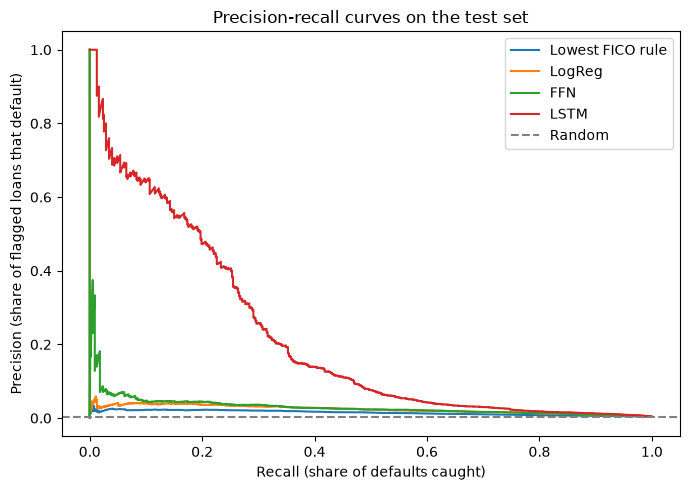

In [25]:
from sklearn.metrics import precision_recall_curve

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

ffn_test_loader = to_loader([X_test], y_test, batch_size=4096)
seq_test_loader = to_loader([seq_test, X_test], y_test, batch_size=4096)
fico_test = df.loc[df["split"] == "test", "fico"].values

test_scores = {
    "Lowest FICO rule": -np.nan_to_num(fico_test, nan=850),
    "LogReg": logreg.predict_proba(X_test)[:, 1],
    "FFN": torch.sigmoid(predict(ffn, ffn_test_loader)).numpy(),
    "LSTM": torch.sigmoid(predict(lstm, seq_test_loader)).numpy(),
}

test_results = pd.DataFrame({name: evaluate(y_test, s) for name, s in test_scores.items()}).T
print(test_results.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
for name, s in test_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, s)
    ax.plot(recall, precision, label=name)
ax.axhline(y_test.mean(), color="gray", linestyle="--", label="Random")
ax.set_xlabel("Recall (share of defaults caught)")
ax.set_ylabel("Precision (share of flagged loans that default)")
ax.set_title("Precision-recall curves on the test set")
ax.legend()
plt.tight_layout()
plt.show()

# keep the test predictions for the analysis in the next section
test_df = df[df["split"] == "test"].copy()
test_df["p_logreg"] = test_scores["LogReg"]
test_df["p_lstm"] = test_scores["LSTM"]

The test results are very close to the validation results, so the conclusions hold on data that was never used to make any decision. The LSTM has a ROC-AUC of 0.903, a PR-AUC of 0.214 and catches 58.2% of the defaults in the top 5%. The logistic regression and the feed-forward network perform the same (ROC-AUC 0.849, recall at top 5% of about 36%), and the credit score rule is the weakest (25.7%). So adding the payment history increases the share of defaults caught in the top 5% from about 36% to 58%, and the PR-AUC is about 7 times higher than the origination-only models.

The precision-recall curves show where this difference comes from. For the LSTM, the loans with the highest predicted risk almost all default, so the precision is close to 1 at low recall. These are probably loans that are already 30-89 days late at month 12. The precision then goes down as more loans are flagged, but it stays far above the other models. The origination-only models stay close to the bottom: they can find borrowers with a higher risk, but they can't find a group of loans that are very likely to default, because most borrowers with a low credit score or a high DTI still pay on time.

## 10. Using the Model

### 10.1 Early-warning list

Here I use the model the way a lender would. Each month, an analyst team can only review a limited number of loans, so the lender ranks all loans by predicted risk and reviews the top of the list. I check how many of the future defaults are caught if the team can review 1%, 2%, 5%, 10% or 20% of the loans, and compare the LSTM with the logistic regression and with simply picking the loans with the lowest credit scores.

For each list size, I also look at the precision, which tells the lender how many of the reviewed borrowers will actually default.

Share of defaults caught (%):
                Credit score rule  LogReg  LSTM
share reviewed                                 
1%                            5.6     9.6  36.5
2%                           10.7    18.6  47.0
5%                           25.7    36.0  58.2
10%                          41.2    53.2  70.9
20%                          59.7    74.5  81.6 

LSTM early-warning list:
                loans reviewed  defaults caught  recall  precision
share reviewed                                                    
1%                        1334              202   0.365      0.151
2%                        2669              260   0.470      0.097
5%                        6672              322   0.582      0.048
10%                      13345              392   0.709      0.029
20%                      26690              451   0.816      0.017


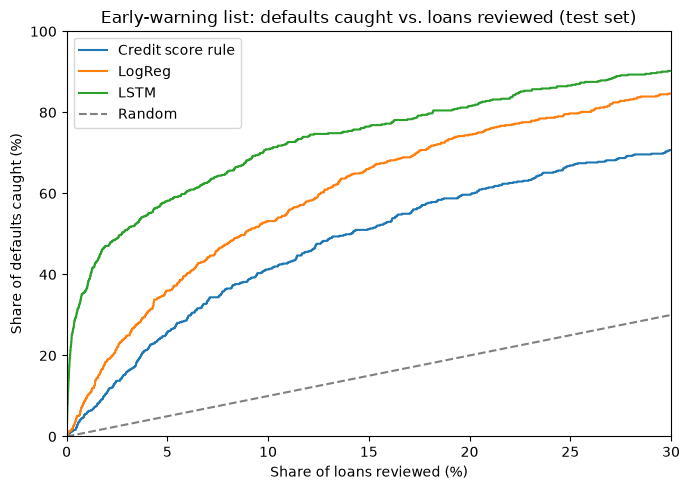

In [26]:
def capture_table(y, scores, rates=(0.01, 0.02, 0.05, 0.10, 0.20)):
    y_sorted = y[np.argsort(scores)[::-1]]
    rows = []
    for r in rates:
        n_review = int(len(y) * r)
        caught = y_sorted[:n_review].sum()
        rows.append({"share reviewed": f"{r:.0%}", "loans reviewed": n_review,
                     "defaults caught": caught, "recall": caught / y.sum(),
                     "precision": caught / n_review})
    return pd.DataFrame(rows).set_index("share reviewed")

warning_scores = {"Credit score rule": test_scores["Lowest FICO rule"],
                  "LogReg": test_df["p_logreg"].values,
                  "LSTM": test_df["p_lstm"].values}
tables = {name: capture_table(y_test, s) for name, s in warning_scores.items()}

recall_summary = pd.DataFrame({name: t["recall"] for name, t in tables.items()}) * 100
print("Share of defaults caught (%):")
print(recall_summary.round(1), "\n")
print("LSTM early-warning list:")
print(tables["LSTM"].round(3))

fig, ax = plt.subplots(figsize=(7, 5))
x = np.arange(1, len(y_test) + 1) / len(y_test)
for name, s in warning_scores.items():
    caught = np.cumsum(y_test[np.argsort(s)[::-1]]) / y_test.sum()
    ax.plot(x * 100, caught * 100, label=name)
ax.plot([0, 100], [0, 100], color="gray", linestyle="--", label="Random")
ax.set_xlim(0, 30)
ax.set_ylim(0, 100)
ax.set_xlabel("Share of loans reviewed (%)")
ax.set_ylabel("Share of defaults caught (%)")
ax.set_title("Early-warning list: defaults caught vs. loans reviewed (test set)")
ax.legend()
plt.tight_layout()
plt.show()

The LSTM is much better than the other methods when the list is short. If the team reviews only 1% of the loans (1,334 loans in the test set), the LSTM catches 36.5% of the defaults, compared with 9.6% for the logistic regression and 5.6% for the credit score rule. With 2%, it catches 47%. In this 1% list, 15% of the borrowers actually default, about 37 times the average default rate of 0.4%.

The advantage gets smaller as the list gets longer: at 20%, the LSTM catches 81.6% of the defaults and the logistic regression 74.5%. This makes sense because most of the LSTM's advantage comes from the small group of loans (about 2.5%) that were already late in the first 12 months. Once the list is longer than this group, the LSTM has to rely on the origination features like the logistic regression.

There are also diminishing returns. Going from 1% to 2% adds 58 defaults for 1,335 extra loans (about 4.3% of the extra loans default), but going from 10% to 20% adds only 59 defaults for 13,345 extra loans (about 0.4%, the same as picking loans at random). So for a lender with limited resources, a short list of 1-2% of the loans is where the model is most useful.

### 10.2 How the model performs across borrower groups

A model can work well overall but poorly for some groups of borrowers. In credit risk this matters for two reasons: the lender needs to know where the model can be trusted, and errors that fall more on some groups can be unfair to those borrowers.

I use the LSTM's top 5% list on the test set and compare the results across credit score bands, LTV bands, regions (Florida, Texas and the other states, because of the hurricanes) and first-time homebuyers. For each group I look at:

- the actual default rate and the average predicted probability, to see if the model under- or overestimates the risk of the group,
- the share of loans flagged, and the recall (share of the group's defaults that are flagged),
- the ROC-AUC inside the group, which shows how well the model ranks borrowers within the same group.

Some groups have few defaults in the test set, so their numbers are less reliable.

In [27]:
threshold = np.quantile(test_df["p_lstm"], 0.95)
test_df["flagged"] = test_df["p_lstm"] >= threshold

def group_report(data, col):
    rows = []
    for group, d in data.groupby(col, observed=True):
        y, p = d["default"].values, d["p_lstm"].values
        rows.append({col: group,
                     "loans": len(d),
                     "defaults": y.sum(),
                     "default rate %": y.mean() * 100,
                     "avg predicted %": p.mean() * 100,
                     "flagged %": d["flagged"].mean() * 100,
                     "recall %": d.loc[d["default"] == 1, "flagged"].mean() * 100,
                     "ROC-AUC": roc_auc_score(y, p) if 0 < y.sum() < len(y) else np.nan})
    return pd.DataFrame(rows).set_index(col).round(2)

for col in ["fico_band", "ltv_band", "region", "first_time_buyer"]:
    display(group_report(test_df, col))

,loans,defaults,default rate %,avg predicted %,flagged %,recall %,ROC-AUC
fico_band,,,,,,,
"(0, 660]",6678,142,2.13,1.66,28.12,74.65,0.82
"(660, 700]",16908,174,1.03,0.81,13.82,66.09,0.85
"(700, 740]",28830,114,0.40,0.35,5.99,57.89,0.89
"(740, 780]",40244,87,0.22,0.13,1.46,29.89,0.87
"(780, 850]",40790,36,0.09,0.05,0.35,25.00,0.85


,loans,defaults,default rate %,avg predicted %,flagged %,recall %,ROC-AUC
ltv_band,,,,,,,
"(0.0, 60.0]",28379,79,0.28,0.23,3.34,48.10,0.87
"(60.0, 70.0]",18589,69,0.37,0.30,4.66,57.97,0.90
"(70.0, 80.0]",52572,180,0.34,0.26,4.22,57.78,0.92
"(80.0, 90.0]",14620,66,0.45,0.39,6.22,62.12,0.91
"(90.0, inf]",19288,159,0.82,0.55,8.97,62.26,0.88


,loans,defaults,default rate %,avg predicted %,flagged %,recall %,ROC-AUC
region,,,,,,,
FL,8473,128,1.51,1.07,32.46,70.31,0.78
Other,115507,345,0.30,0.24,2.51,56.81,0.91
TX,9472,80,0.84,0.54,10.84,45.00,0.80


,loans,defaults,default rate %,avg predicted %,flagged %,recall %,ROC-AUC
first_time_buyer,,,,,,,
9,1,0,0.00,0.39,0.00,NaN,NaN
N,113428,435,0.38,0.30,4.76,57.47,0.90
Y,20023,118,0.59,0.40,6.37,61.02,0.89


The model ranks borrowers well inside every group: the ROC-AUC within each credit score and LTV band is between 0.82 and 0.92, so it is not just separating borrowers by credit score. But there are a few important differences between groups.

Credit score: borrowers below 660 have a default rate of 2.1%, and 28% of them are flagged. The model catches 75% of their defaults, but only 25-30% of the defaults among borrowers above 740. This also means most of the false alarms fall on low credit score borrowers: since only 2.1% of them default, the large majority of the flagged borrowers in this group would have paid. If the lender uses the list to offer help (a call or a payment plan), this is not a big problem. If it is used for negative actions, such as tightening credit, these borrowers would carry an unfair share of the errors.

Region: the model works worse in Florida and Texas. The ROC-AUC is 0.78 in Florida and 0.80 in Texas, compared with 0.91 in the other states, and the recall in Texas is only 45%. These are the states hit by the 2017 hurricanes, and defaults caused by a natural disaster don't show up in the earlier payment history or in the origination data. So the model is not reliable for this kind of sudden shock.

First-time homebuyers: the results are very similar to other borrowers (recall 61% vs. 57%, ROC-AUC 0.89 vs. 0.90).

Finally, the average predicted probability is below the actual default rate in every group, and the gap is larger in the high-risk groups and in Florida and Texas. The model is good at ranking loans, but its probabilities would need to be calibrated before being used for something like loss provisions.

### 10.3 Defaults the model catches and misses

In the test set, the top 5% list catches 322 of the 553 defaults and misses 231. Here I compare the caught and missed defaults to understand what kind of risk the model can and cannot detect. For each group I look at:

- the share of loans that were late at least once in the first 12 months,
- the average credit score, DTI and LTV,
- the share in Florida or Texas, and the share from 2016 Q1 (the hurricane quarter),
- when the default happens within months 13 to 24.

I also show a few examples of missed defaults from borrowers who were never late in the first 12 months.

result,Caught,Missed
loans,322.00,231.00
late_in_months_1_12_pct,71.12,1.30
avg_fico,682.24,717.01
avg_dti,38.77,36.70
avg_ltv,80.52,76.90
florida_texas_pct,39.13,35.50
quarter_2016Q1_pct,45.34,47.62
avg_default_month,18.22,20.43
avg_predicted_pct,21.84,0.30


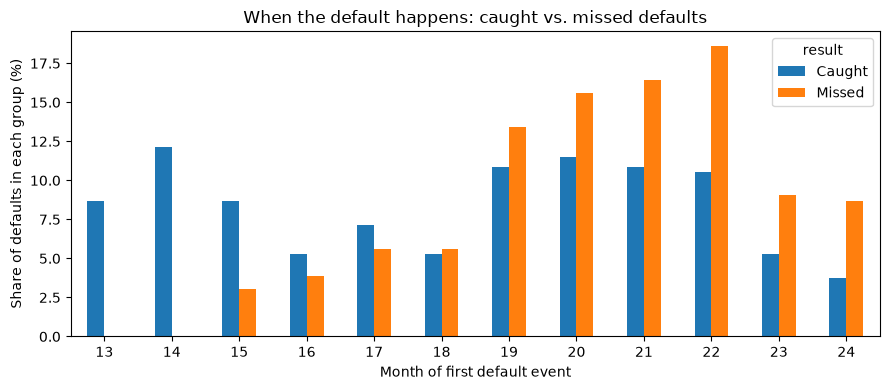

,fico,dti,ltv,state,quarter,default_month,p_lstm
847198,807.0,NaN,102.0,MI,2017Q1,19,0.0001
359521,779.0,43.0,80.0,FL,2016Q1,22,0.0056
66846,744.0,NaN,72.0,NV,2015Q1,22,0.0015
811957,770.0,NaN,88.0,WA,2017Q1,22,0.0015
106544,689.0,42.0,80.0,CA,2015Q1,19,0.0018


In [28]:
defaults = test_df[test_df["default"] == 1].copy()
defaults["result"] = np.where(defaults["flagged"], "Caught", "Missed")

# month of the first default event (13 to 24)
first_bad_t = perf.loc[in_window & is_bad].groupby("loan_id", observed=True)["t"].min()
obs_t = obs.set_index("loan_id")["t"]
ids = defaults["loan_id"].astype(str)
defaults["default_month"] = ids.map(first_bad_t.rename(index=str)) - ids.map(obs_t.rename(index=str)) + 12

summary = defaults.groupby("result").agg(
    loans=("default", "size"),
    late_in_months_1_12_pct=("months_late", lambda s: (s > 0).mean() * 100),
    avg_fico=("fico", "mean"),
    avg_dti=("dti", "mean"),
    avg_ltv=("ltv", "mean"),
    florida_texas_pct=("region", lambda s: s.isin(["FL", "TX"]).mean() * 100),
    quarter_2016Q1_pct=("quarter", lambda s: (s == "2016Q1").mean() * 100),
    avg_default_month=("default_month", "mean"),
    avg_predicted_pct=("p_lstm", lambda s: s.mean() * 100),
).round(2).T
display(summary)

timing = pd.crosstab(defaults["default_month"], defaults["result"], normalize="columns") * 100
timing.plot(kind="bar", figsize=(9, 4))
plt.title("When the default happens: caught vs. missed defaults")
plt.xlabel("Month of first default event")
plt.ylabel("Share of defaults in each group (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

examples = defaults[(defaults["result"] == "Missed") & (defaults["months_late"] == 0)]
display(examples[["fico", "dti", "ltv", "state", "quarter", "default_month", "p_lstm"]]
        .sample(5, random_state=42).round(4))

The biggest difference between caught and missed defaults is the payment history. 71% of the caught defaults were late at least once in the first 12 months, compared with only 1.3% of the missed ones. The missed borrowers also look safer at origination (average credit score 717 vs. 682, and slightly lower DTI and LTV), and the model gives them an average default probability of 0.30%, which is about the same as an average loan. So from the model's point of view, these borrowers look completely normal at month 12.

Timing also matters. The caught defaults often happen early, in months 13 to 15, and the model catches all the defaults in months 13 and 14. The missed defaults are concentrated in months 19 to 22. The further the default is from the observation point, the more likely the problem started after month 12 (for example a job loss or an illness), which the model has no way to see. The five examples confirm this: credit scores between 689 and 807, predicted probabilities below 0.6%, and defaults in months 19 to 22.

I expected the missed defaults to come more from Florida and Texas because of the hurricanes, but the shares are similar (36% of missed vs. 39% of caught). The reason is that the model flags 32% of the Florida loans, because it learned from the training set that Florida loans default more. This works on the test set, because the training and test sets cover the same period and the same hurricanes. But in real use, the model would predict future loans, and the next disaster could happen somewhere else. So part of the performance in Florida and Texas would probably not carry over to a different period. This is a limitation of splitting the loans randomly instead of by time.

### 10.4 Robustness check: predicting a later quarter

So far, the loans were split randomly, so the training and test sets cover the same period and the same events, like the 2017 hurricanes. In real use, a lender trains the model on past loans and applies it to newer ones. To check how the model does in this situation, I train a new LSTM and a new logistic regression only on the 2015 Q1 and 2016 Q1 loans, and test them on the 2017 Q1 loans, which the models have never seen. The 2017 Q1 loans also have their months 13 to 24 in 2018-2019, a later period than the training loans.

I use the same settings as before (12 months of history, no class weights, 10 epochs). I compare the results on the 2017 Q1 loans in the original test set with the models from the random split, and I also evaluate the new models on all 2017 Q1 loans, since the test set alone has fewer defaults.

In [29]:
torch.set_num_threads(2)   # use fewer CPU cores so the computer doesn't overheat

q = df["quarter"].values
s = df["split"].values
X_all = X.values

tr = (s == "train") & (q != "2017Q1")
va = (s == "val") & (q != "2017Q1")
te = (s == "test") & (q == "2017Q1")
all_2017 = q == "2017Q1"
print(f"Train: {tr.sum():,} loans | Validation: {va.sum():,} | "
      f"2017Q1 test loans: {te.sum():,} ({y[te].sum()} defaults) | "
      f"All 2017Q1 loans: {all_2017.sum():,} ({y[all_2017].sum()} defaults)")

torch.manual_seed(42)
lstm_oot = SeqModel(n_seq_features=seq.shape[2], n_static=X_all.shape[1], rnn_type="lstm")
lstm_oot, lstm_oot_history = train_or_load(
    "lstm_oot", lstm_oot,
    to_loader([seq[tr], X_all[tr]], y[tr], shuffle=True),
    to_loader([seq[va], X_all[va]], y[va], batch_size=4096),
    y[va], epochs=10, lr=1e-3)

logreg_oot = LogisticRegression(max_iter=1000)
logreg_oot.fit(X_all[tr], y[tr])

def lstm_scores(model, mask):
    loader = to_loader([seq[mask], X_all[mask]], y[mask], batch_size=4096)
    return torch.sigmoid(predict(model, loader)).numpy()

test_2017 = (test_df["quarter"] == "2017Q1").values
oot_results = {
    "LogReg, random split": evaluate(y[te], test_df["p_logreg"].values[test_2017]),
    "LogReg, trained on 2015-16": evaluate(y[te], logreg_oot.predict_proba(X_all[te])[:, 1]),
    "LSTM, random split": evaluate(y[te], test_df["p_lstm"].values[test_2017]),
    "LSTM, trained on 2015-16": evaluate(y[te], lstm_scores(lstm_oot, te)),
    "LogReg, trained on 2015-16 (all 2017Q1)": evaluate(y[all_2017], logreg_oot.predict_proba(X_all[all_2017])[:, 1]),
    "LSTM, trained on 2015-16 (all 2017Q1)": evaluate(y[all_2017], lstm_scores(lstm_oot, all_2017)),
}
pd.DataFrame(oot_results).T.round(4)

Train: 435,367 loans | Validation: 93,293 | 2017Q1 test loans: 40,159 (174 defaults) | All 2017Q1 loans: 267,723 (1158 defaults)
Loaded saved model: lstm_oot


,ROC-AUC,PR-AUC,Recall@top5%
"LogReg, random split",0.8095,0.0198,0.2931
"LogReg, trained on 2015-16",0.7981,0.0173,0.2701
"LSTM, random split",0.8841,0.2671,0.6092
"LSTM, trained on 2015-16",0.8741,0.2143,0.5690
"LogReg, trained on 2015-16 (all 2017Q1)",0.7876,0.0152,0.2211
"LSTM, trained on 2015-16 (all 2017Q1)",0.8676,0.1690,0.5415


When the models are trained only on 2015 Q1 and 2016 Q1 loans and tested on 2017 Q1 loans, the performance drops a little but stays close. On the same 2017 Q1 test loans, the ROC-AUC goes down by about 0.01 for both models, and the recall at top 5% goes from 60.9% to 56.9% for the LSTM and from 29.3% to 27.0% for the logistic regression. So the random split was slightly optimistic, but the model mostly learned patterns that also work in a later period.

On all 2017 Q1 loans (1,158 defaults, a more reliable estimate), the LSTM trained on earlier loans catches 54.2% of the defaults in the top 5%, compared with 22.1% for the logistic regression. The gap between the two models is even larger than with the random split. This suggests that the payment history signal (payments getting worse before a default) is more stable over time than the relationship between the origination variables and default, which can change with local events like the hurricanes.

The 2017 Q1 test set only has 174 defaults, and the same model gets a recall of 56.9% on it but 54.2% on all 2017 Q1 loans, so differences of a few percentage points between these numbers should not be over-interpreted.

## 11. Conclusion and Limitations

### 11.1 Conclusion

The goal of this project was to test whether the payment history in the first 12 months of a mortgage helps predict serious delinquency in months 13 to 24. The answer is yes, and the effect is large. On the test set, the LSTM that reads 12 months of payment history together with the origination data has a ROC-AUC of 0.903 and a PR-AUC of 0.214, and it catches 58.2% of the defaults in the top 5% of loans. The logistic regression and the feed-forward network with only the origination data catch about 36%, and simply picking the lowest credit scores catches 25.7%. The difference is even bigger for a short list: if a lender reviews only 1% of the loans, the LSTM catches 36.5% of the defaults, compared with 9.6% for the logistic regression.

The experiments showed that:

- 10 to 15 epochs are enough. Training longer doesn't help and the model starts to overfit after about 15 epochs.
- The LSTM and the GRU perform the same, so the simpler GRU would also work for 12-month sequences.
- About 6 months of history is enough. Using only 3 months is clearly worse, but even 3 months is much better than no history at all.
- Class weights don't improve the ranking, and they make the predicted probabilities much too high (2.4% and 14.6% on average with weights of 10 and 100, compared with an actual default rate of 0.41%).

When the model is trained only on the 2015 Q1 and 2016 Q1 loans and tested on the 2017 Q1 loans, the ROC-AUC drops by only about 0.01, and the LSTM still catches 54.2% of the defaults in the top 5% compared with 22.1% for the logistic regression. So the main result also holds for a later group of loans.

### 11.2 Limitations

- Many defaults can't be predicted from this data. 57% of all defaults come from loans that were never late in the first 12 months, and almost all the defaults the model misses (228 of 231 in the test set) are from these loans. They often happen late in the window (months 19 to 22), probably because of events after month 12, like a job loss, that are not in the data.
- The model is weaker for sudden shocks. The ROC-AUC is 0.78 in Florida and 0.80 in Texas, compared with 0.91 in the other states, because of the 2017 hurricanes. Part of the performance in these states comes from the model learning that Florida loans defaulted more in the same period, which may not carry over to the next disaster.
- The predicted probabilities are too low on average (0.32% vs. 0.41% in the validation set), and more so for the high-risk groups. The model is good for ranking loans, but the probabilities would need to be calibrated before being used for loss provisions.
- The data only covers fixed-rate Freddie Mac loans originated in the first quarter of 2015, 2016 and 2017, and the label windows are in 2016-2019, a period with a good economy. I excluded the COVID period, so I don't know how the model would do in a recession.
- The validation and test sets only have about 550 defaults each, so the results can change by 1-2 percentage points just from which loans end up in each set.
- The main split is random by loan, so the training and test sets cover the same period. The out-of-time check shows this makes the results only slightly optimistic, but it was tested on one later quarter only.

### 11.3 What I would do with more time

- Calibrate the predicted probabilities (for example with Platt scaling or isotonic regression).
- Add more quarters and later years, including the COVID period as a separate stress test.
- Add economic variables such as local unemployment and house prices, and the disaster flag in the Freddie Mac data, to help with sudden shocks.
- Use several observation points per loan instead of only month 12, so the model can be used at any time during the life of the loan.